In [29]:
import numpy as np
import scanpy as sc
import umap
import INSPIRE
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import anndata as ad
import scipy.sparse
import os
from sklearn.metrics import pairwise_distances
from sklearn.metrics import silhouette_score
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.metrics.cluster import normalized_mutual_info_score
from annoy import AnnoyIndex

In [30]:
data_dir = '/data/hoan/spatial_transcriptomics/data/SDMBench/Data/378k/BrainAgingSpatialAtlas_MERFISH.h5ad'
adata=sc.read_h5ad(data_dir)
adata.shape

(378918, 374)

In [3]:
adata.obs["slice_stage"] = [adata.obs["slice"][i] + "_" + adata.obs["development_stage"][i] for i in range(adata.shape[0])]
adata.obs["slice_stage_donor"] = [adata.obs["slice_stage"][i] + "_" + adata.obs["donor_id"][i] for i in range(adata.shape[0])]
adata.obs['Region'] = adata.obs['tissue']
adata.X = adata.raw.X
adata.obsm["spatial"] = adata.obsm["X_spatial_coords"]
set(adata.obs["slice_stage_donor"].values)

{'0_20-month-old stage and over_MsBrainAgingSpatialDonor_2',
 '0_20-month-old stage and over_MsBrainAgingSpatialDonor_3',
 '0_20-month-old stage and over_MsBrainAgingSpatialDonor_5',
 '0_20-month-old stage and over_MsBrainAgingSpatialDonor_6',
 '0_20-month-old stage and over_MsBrainAgingSpatialDonor_9',
 '0_24-week-old stage_MsBrainAgingSpatialDonor_10',
 '0_24-week-old stage_MsBrainAgingSpatialDonor_11',
 '0_24-week-old stage_MsBrainAgingSpatialDonor_12',
 '0_4-week-old stage_MsBrainAgingSpatialDonor_1',
 '0_4-week-old stage_MsBrainAgingSpatialDonor_4',
 '0_4-week-old stage_MsBrainAgingSpatialDonor_7',
 '0_4-week-old stage_MsBrainAgingSpatialDonor_8',
 '1_20-month-old stage and over_MsBrainAgingSpatialDonor_2',
 '1_20-month-old stage and over_MsBrainAgingSpatialDonor_3',
 '1_20-month-old stage and over_MsBrainAgingSpatialDonor_5',
 '1_20-month-old stage and over_MsBrainAgingSpatialDonor_6',
 '1_20-month-old stage and over_MsBrainAgingSpatialDonor_9',
 '1_24-week-old stage_MsBrainAging

0_20-month-old stage and over_MsBrainAgingSpatialDonor_2
0_20-month-old stage and over_MsBrainAgingSpatialDonor_3
0_20-month-old stage and over_MsBrainAgingSpatialDonor_5
0_20-month-old stage and over_MsBrainAgingSpatialDonor_6
0_20-month-old stage and over_MsBrainAgingSpatialDonor_9
0_24-week-old stage_MsBrainAgingSpatialDonor_10
0_24-week-old stage_MsBrainAgingSpatialDonor_11
0_24-week-old stage_MsBrainAgingSpatialDonor_12
0_4-week-old stage_MsBrainAgingSpatialDonor_1
0_4-week-old stage_MsBrainAgingSpatialDonor_4
0_4-week-old stage_MsBrainAgingSpatialDonor_7
0_4-week-old stage_MsBrainAgingSpatialDonor_8
1_20-month-old stage and over_MsBrainAgingSpatialDonor_2
1_20-month-old stage and over_MsBrainAgingSpatialDonor_3
1_20-month-old stage and over_MsBrainAgingSpatialDonor_5
1_20-month-old stage and over_MsBrainAgingSpatialDonor_6
1_20-month-old stage and over_MsBrainAgingSpatialDonor_9
1_24-week-old stage_MsBrainAgingSpatialDonor_10
1_24-week-old stage_MsBrainAgingSpatialDonor_11
1_24-w

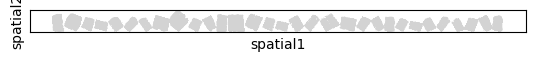

Store counts and library sizes for Poisson modeling...
Normalize data...
Start building graphs...
Build graphs and prepare node features for LGCN networks
Radius for graph connection is 60.0000.
17.0538 neighbors per cell on average.
Node features for slice 0 : (15694, 748)
Radius for graph connection is 60.0000.
17.0776 neighbors per cell on average.
Node features for slice 1 : (19503, 748)
Radius for graph connection is 60.0000.
16.7755 neighbors per cell on average.
Node features for slice 2 : (10744, 748)
Radius for graph connection is 60.0000.
16.1712 neighbors per cell on average.
Node features for slice 3 : (9462, 748)
Radius for graph connection is 60.0000.
15.0942 neighbors per cell on average.
Node features for slice 4 : (11179, 748)
Radius for graph connection is 60.0000.
15.0105 neighbors per cell on average.
Node features for slice 5 : (9665, 748)
Radius for graph connection is 60.0000.
13.4020 neighbors per cell on average.
Node features for slice 6 : (7545, 748)
Radius f

In [8]:
import time
start_time = time.perf_counter()

adata_st_list = []
section_id_list = list(sorted(set(adata.obs["slice_stage_donor"].values)))
for i in range(len(section_id_list)):
    print(section_id_list[i])
    adata_st_list.append(adata[adata.obs["slice_stage_donor"] == section_id_list[i], :].copy())

adata_st_list, adata_full = INSPIRE.utils.preprocess(adata_st_list=adata_st_list,
                                                     num_hvgs=1000,
                                                     min_genes_qc=1,
                                                     min_cells_qc=1,
                                                     spot_size=20,
                                                     limit_num_genes=True)

adata_st_list = INSPIRE.utils.build_graph_LGCN(adata_st_list=adata_st_list,
                                               rad_cutoff_list=[60]*len(adata_st_list))

In [10]:
model = INSPIRE.model.Model_LGCN(adata_st_list=adata_st_list,
                                 n_spatial_factors=30, #may need to choose a suitable number by users
                                 n_training_steps=10000,
                                 batch_size=2048,
                                 different_platforms=False
                                )
model.train(adata_st_list)

adata_full, basis_df = model.eval(adata_st_list, adata_full)
basis = np.array(basis_df.values)

  1%|█▋                                                                                                                                                                           | 1/100 [00:04<06:44,  4.08s/it]

Step: 0, d_loss: 41.9337, Loss: 8696.3457, recon_loss: 7828.5054, fe_loss: 640.0823, geom_loss: 1874.6398, beta_loss: 167.9712, gan_loss: 22.2931


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [04:29<00:00,  2.70s/it]


Add cell/spot proportions of spatial factors into adata_full.obs...
Add cell/spot latent representations into adata_full.obsm['latent']...


In [24]:
import scanpy as sc
from sklearn.mixture import GaussianMixture

n_domains = 8

gmm = GaussianMixture(n_components=n_domains, random_state=42)
gmm_labels = gmm.fit_predict(adata_full.obsm["latent"])

end_time = time.perf_counter()
elapsed_time = end_time - start_time
print(f"Execution time: {elapsed_time:.4f} seconds")

In [26]:
true_labels = adata_full.obs['Region'].values
print(normalized_mutual_info_score(true_labels, gmm_labels))

0.26046097873141083


In [27]:
df_out = pd.DataFrame({'ground_truth': true_labels, 'INSPIRE': gmm_labels})
df_out.to_csv('/data/hoan/spatial_transcriptomics/GraphBG-analysis/output/INSPIRE_BrainAgingSpatialAtlas.csv', index=False)